# Selecting the 75 of the 185 ccepcoreg electrodes that best match the original 75-electrode montage

**Goal.** Train and validate a 75-electrode model that is as close as possible to the original work (same montage), using only electrodes that exist in the ccepcoreg release (185 of the 256 net).

**Method (standard techniques, fixed before looking at any model result)**
1. *Target*: the 75 electrodes of `anatomy/electrode_75.mat` placed in the MNE head frame. 72 exist in MNE's `standard_1005`; `Nz` = the montage's nasion; `TP11`, `TP12` (in no MNE template) via the similarity transform that maps the original coordinates onto the MNE frame, fitted on the 72 shared electrodes.
2. *Candidates*: the 185 released electrodes = GSN-HydroCel-256 template positions (MNE head frame).
3. Both sets are projected onto the **fsaverage scalp surface** (what MNE does with EEG electrodes in a forward solution) and compared there.
4. *One-to-one assignment* (Hungarian algorithm): minimum total distance, minimum total squared distance, minimum worst-case distance (bottleneck), and a naive greedy baseline.
5. *Quality of a subset* = fidelity of its **forward model** (leadfield, same MNE recipe as everywhere in this project) to the forward model of the original montage: per-region topography correlation of the average-referenced region leadfields.
   Rule fixed in advance: the subset with the highest median region correlation is selected (ties: lower global relative error). A random assignment shows the scale.

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, mne
from scipy.io import loadmat, savemat
warnings.filterwarnings("ignore"); mne.set_log_level("ERROR")
HERE = Path.cwd()
if not (HERE / "electrode_selection_75sub.py").exists():
    HERE = HERE / "headmodel_75sub"
sys.path.insert(0, str(HERE))
import electrode_selection_75sub as S
H = S.H
REPO = S.REPO; OUT = HERE / "outputs"; FIG = OUT / "figures"; FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 130, "font.size": 9, "axes.grid": True, "grid.alpha": 0.25})
save = lambda fig, n: fig.savefig(FIG / f"{n}.png", bbox_inches="tight")

labels, pos_t, src_t, fitstat = S.original_montage()
cand_names = [str(e["labels"]) for e in loadmat(str(REPO / "anatomy" / "electrode_185.mat"), simplify_cells=True)["eloc185"]]
pos_c = S.candidate_montage(cand_names)
print(len(labels), "target electrodes;", len(cand_names), "candidates")
print("transform fitted on the %d shared electrodes: scale %.3f, residual median %.1f mm, max %.1f mm; electrodes placed by transform: %s" % (
      fitstat["n_shared"], fitstat["fit_scale"], fitstat["fit_residual_median_mm"], fitstat["fit_residual_max_mm"], fitstat["missing"]))
print("check: Nz from the transform vs the montage nasion differ by %.1f mm (the nasion is used)" % fitstat["nz_transform_vs_nasion_mm"])

75 target electrodes; 185 candidates
transform fitted on the 72 shared electrodes: scale 1.049, residual median 4.3 mm, max 19.0 mm; electrodes placed by transform: ['Nz', 'TP11', 'TP12']
check: Nz from the transform vs the montage nasion differ by 7.0 mm (the nasion is used)


## 1. Both sets on the fsaverage scalp

distance moved by the projection onto the scalp (mm): original montage median 2.1 / max 12.6 ; GSN candidates median 6.9 / max 16.3
closest candidate to each target (lower bound for any assignment): median 8.4 mm, 90th pct 19.1, max 31.9; targets with no candidate within 15 mm: 10, within 25 mm: 4
targets with the farthest closest candidate (mm): {'TP11': 31.9, 'TP10': 30.0, 'TP9': 28.9, 'TP12': 27.8, 'F10': 23.9, 'F9': 23.3, 'FT10': 22.8, 'FT9': 21.6, 'Cz': 15.3, 'CP1': 15.1, 'AF3': 14.9, 'Pz': 14.8}


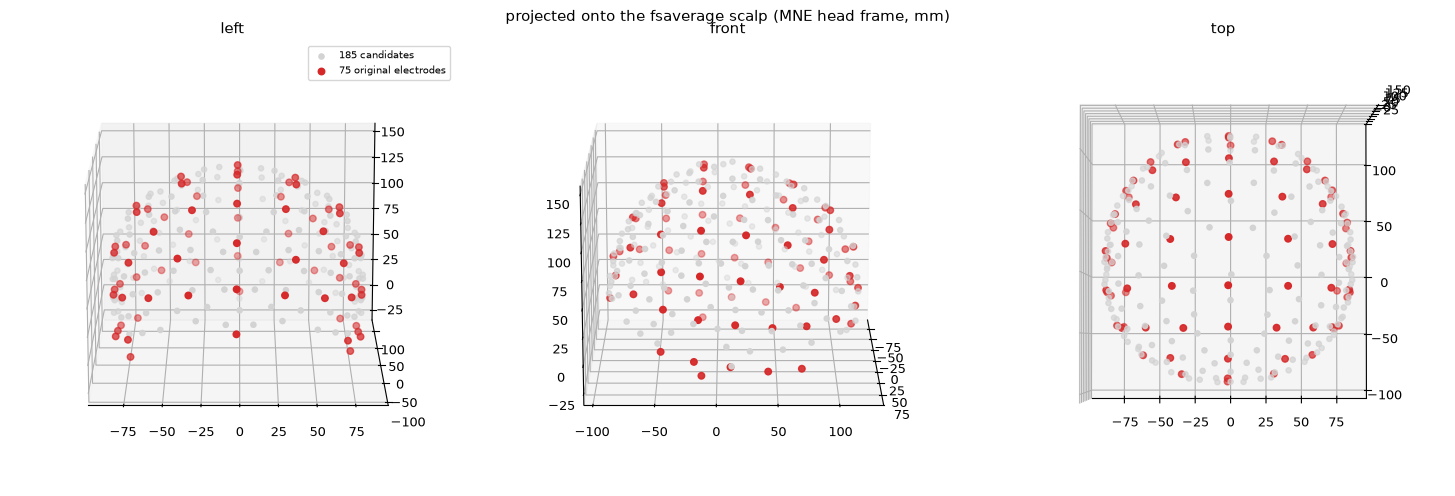

In [2]:
surf, trans = S.scalp_surface()
pt = S.project_to_scalp(pos_t, surf, trans); pc = S.project_to_scalp(pos_c, surf, trans)
shift_t = np.linalg.norm(pt - pos_t, axis=1) * 1e3; shift_c = np.linalg.norm(pc - pos_c, axis=1) * 1e3
print("distance moved by the projection onto the scalp (mm): original montage median %.1f / max %.1f ; GSN candidates median %.1f / max %.1f" % (np.median(shift_t), shift_t.max(), np.median(shift_c), shift_c.max()))
D = np.linalg.norm(pt[:, None] - pc[None], axis=2) * 1e3            # (75, 185) mm between projected points
nn = D.min(axis=1)
print("closest candidate to each target (lower bound for any assignment): median %.1f mm, 90th pct %.1f, max %.1f; targets with no candidate within 15 mm: %d, within 25 mm: %d" % (
      np.median(nn), np.percentile(nn, 90), nn.max(), (nn > 15).sum(), (nn > 25).sum()))
far = pd.Series(nn, index=labels).sort_values(ascending=False).head(12); print("targets with the farthest closest candidate (mm):", far.round(1).to_dict())
fig = plt.figure(figsize=(15, 5))
for k, (e, a, ttl) in enumerate([(15, -90, "left"), (15, 0, "front"), (88, -90, "top")]):
    ax = fig.add_subplot(1, 3, k + 1, projection="3d")
    ax.scatter(*(pc * 1e3).T, c="lightgray", s=14, label="185 candidates"); ax.scatter(*(pt * 1e3).T, c="tab:red", s=22, label="75 original electrodes")
    ax.view_init(e, a); ax.set_title(ttl)
    if k == 0: ax.legend(fontsize=7)
fig.suptitle("projected onto the fsaverage scalp (MNE head frame, mm)"); fig.tight_layout(); save(fig, "fig70_targets_and_candidates"); plt.show()

## 2. Candidate assignments

In [3]:
assign = S.candidate_assignments(D)
rows = []
for k, a in assign.items():
    d = D[np.arange(75), a]
    rows.append(dict(method=k, unique_candidates=len(set(a)), sum_mm=d.sum(), mean_mm=d.mean(), median_mm=np.median(d), p95_mm=np.percentile(d, 95), max_mm=d.max()))
dist_tab = pd.DataFrame(rows).set_index("method"); print(dist_tab.round(2))
dup = (np.argmin(D, axis=1)); print("naive nearest candidate per target (not one-to-one): %d distinct candidates for 75 targets -> %d duplicates (not allowed)" % (len(set(dup)), 75 - len(set(dup))))

               unique_candidates  sum_mm  mean_mm  median_mm  p95_mm  max_mm
method                                                                      
hungarian_sum                 75  766.03    10.21       8.41   26.05   42.39
hungarian_sq                  75  781.20    10.42       8.66   25.10   31.86
greedy                        75  780.01    10.40       8.41   25.44   50.69
bottleneck                    75  781.20    10.42       8.66   25.10   31.86
naive nearest candidate per target (not one-to-one): 73 distinct candidates for 75 targets -> 2 duplicates (not allowed)


## 3. Quality of each subset: fidelity of its forward model to the original montage's forward model

In [4]:
rm = H.region_mapping(REPO)
L_t = S.target_leadfield(labels, pos_t, rm, cache=OUT / "vertex_leadfield_75target.npy")          # (75, 994): original montage on the MNE template
cache185 = REPO / "headmodel_185" / "outputs" / "vertex_leadfield_185ch.npy"
assert cache185.exists(), "run headmodel_185/build_headmodel_185.py first"
L_c = H.sum_by_region(np.load(cache185).astype(float), rm)                                         # (185, 994)
res, per_region = {}, {}
for k, a in assign.items():
    f, corr, rel = S.region_topography_fidelity(L_t, L_c[a]); res[k] = f; per_region[k] = corr
rng = np.random.default_rng(0); rnd = []
for _ in range(100):
    rnd.append(S.region_topography_fidelity(L_t, L_c[rng.permutation(185)[:75]])[0]["corr_median"])
res["random assignment (mean of 100)"] = dict(corr_median=float(np.mean(rnd)), corr_p05=np.nan, corr_min=np.nan, rel_err_median=np.nan, rel_err_p95=np.nan, rel_err_global=np.nan)
fid = pd.DataFrame(res).T; print(fid.round(4))

                                 corr_median  corr_p05  corr_min  \
hungarian_sum                         0.9896    0.9750    0.9167   
hungarian_sq                          0.9900    0.9773    0.9317   
greedy                                0.9891    0.9738    0.9244   
bottleneck                            0.9900    0.9773    0.9317   
random assignment (mean of 100)      -0.0098       NaN       NaN   

                                 rel_err_median  rel_err_p95  rel_err_global  
hungarian_sum                            0.1469       0.2312          0.1558  
hungarian_sq                             0.1450       0.2294          0.1503  
greedy                                   0.1510       0.2368          0.1578  
bottleneck                               0.1450       0.2294          0.1503  
random assignment (mean of 100)             NaN          NaN             NaN  


## 4. Selection (rule fixed in advance: highest median region correlation; ties -> lower global error)

selected: hungarian_sq | median region correlation 0.9900, 5th pct 0.9773, min 0.932, global relative error 0.150
distance between each original electrode and its selected electrode (projected on the scalp): median 8.7 mm, 90th pct 21.1, max 31.9; <10 mm: 43, 10-20 mm: 23, >20 mm: 9
original_label selected_electrode  idx185  distance_mm                         original_position_source
          TP11                E67      66        31.86 similarity transform of the original coordinates
          TP10               E191     159        30.95                                MNE standard_1005
           TP9                E68      67        28.94                                MNE standard_1005
          TP12               E219     179        27.79 similarity transform of the original coordinates
           F10                E10       9        23.94                                MNE standard_1005
            F9                E46      45        23.30                                MNE st

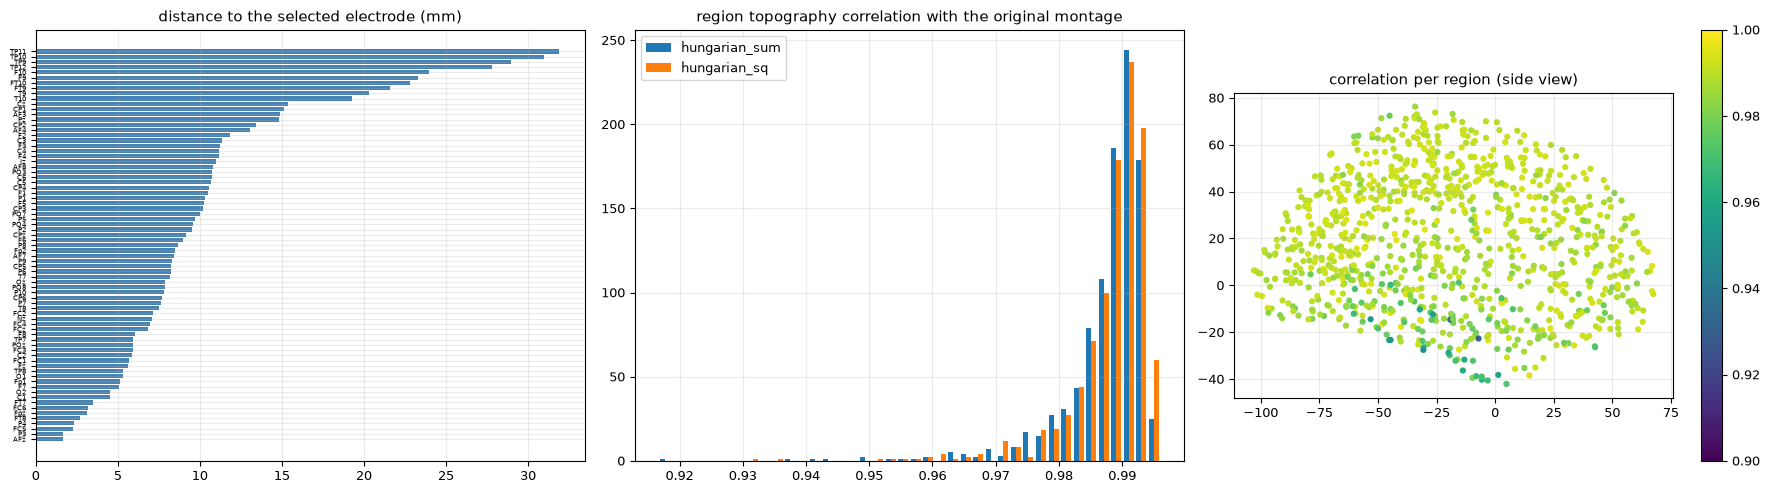

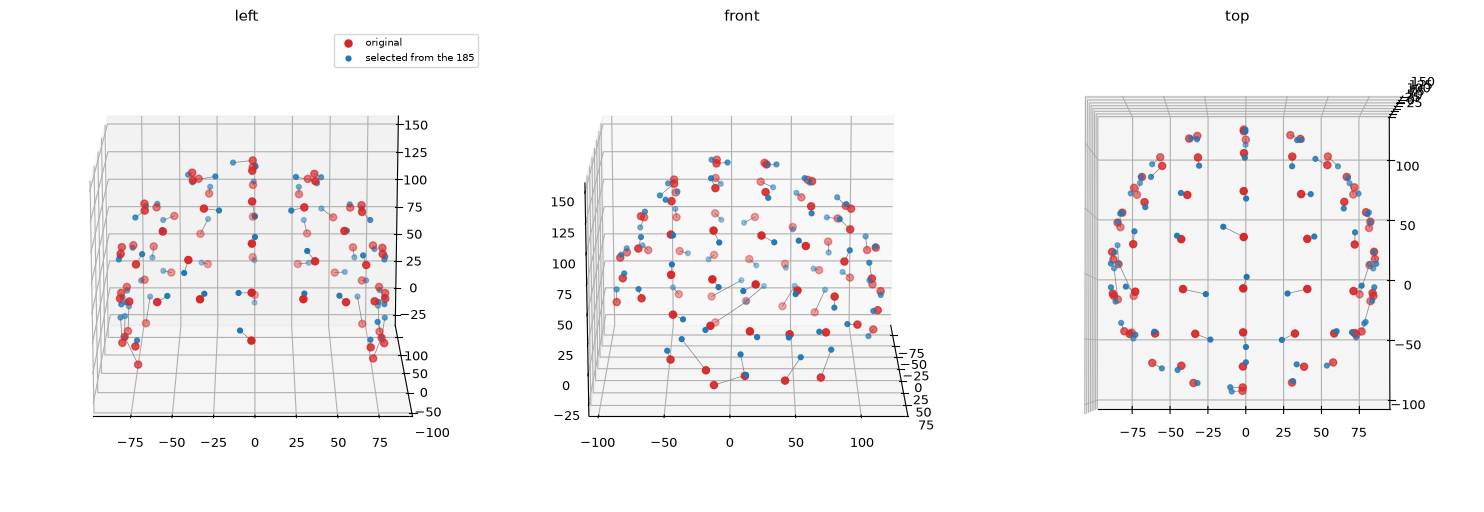

In [5]:
cands = fid.drop(index=[i for i in fid.index if i.startswith("random")]).sort_values(["corr_median", "rel_err_global"], ascending=[False, True])
best = cands.index[0]
print("selected:", best, "| median region correlation %.4f, 5th pct %.4f, min %.3f, global relative error %.3f" % (cands.loc[best, "corr_median"], cands.loc[best, "corr_p05"], cands.loc[best, "corr_min"], cands.loc[best, "rel_err_global"]))
idx = assign[best]; d_sel = D[np.arange(75), idx]
sel = pd.DataFrame(dict(original_label=labels, selected_electrode=[cand_names[j] for j in idx], idx185=idx, distance_mm=d_sel.round(2), original_position_source=src_t))
print("distance between each original electrode and its selected electrode (projected on the scalp): median %.1f mm, 90th pct %.1f, max %.1f; <10 mm: %d, 10-20 mm: %d, >20 mm: %d" % (
      np.median(d_sel), np.percentile(d_sel, 90), d_sel.max(), (d_sel < 10).sum(), ((d_sel >= 10) & (d_sel < 20)).sum(), (d_sel >= 20).sum()))
print(sel.sort_values("distance_mm", ascending=False).head(12).to_string(index=False))
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
o = np.argsort(d_sel); ax[0].barh(range(75), d_sel[o], color="steelblue"); ax[0].set_yticks(range(75)); ax[0].set_yticklabels(np.array(labels)[o], fontsize=5); ax[0].set_title("distance to the selected electrode (mm)")
ax[1].hist([per_region["hungarian_sum"], per_region[best] if best != "hungarian_sum" else per_region["greedy"]], bins=40, label=["hungarian_sum", best if best != "hungarian_sum" else "greedy"]); ax[1].set_title("region topography correlation with the original montage"); ax[1].legend()
ctx = loadmat(str(REPO / "anatomy" / "fs_cortex_20k.mat"), simplify_cells=True)["pos"]; cent = np.array([ctx[rm == r].mean(0) for r in range(994)])
sc = ax[2].scatter(cent[:, 1], cent[:, 2], c=per_region[best], s=12, cmap="viridis", vmin=0.9, vmax=1); plt.colorbar(sc, ax=ax[2]); ax[2].set_title("correlation per region (side view)"); ax[2].set_aspect("equal")
fig.tight_layout(); save(fig, "fig71_selection_quality"); plt.show()
fig = plt.figure(figsize=(15, 5))
for k, (e, a, ttl) in enumerate([(15, -90, "left"), (15, 0, "front"), (88, -90, "top")]):
    ax = fig.add_subplot(1, 3, k + 1, projection="3d")
    ax.scatter(*(pt * 1e3).T, c="tab:red", s=26, label="original")
    ax.scatter(*(pc[idx] * 1e3).T, c="tab:blue", s=12, label="selected from the 185")
    for i, j in enumerate(idx): ax.plot(*np.c_[pt[i], pc[j]] * 1e3, c="gray", lw=0.5)
    ax.view_init(e, a); ax.set_title(ttl)
    if k == 0: ax.legend(fontsize=7)
fig.tight_layout(); save(fig, "fig72_selected_vs_original"); plt.show()

## 5. Practical check: are the selected electrodes often flagged as bad in the validation data?

In [6]:
bad = pd.read_csv(REPO / "document" / "validation_data_preprocessing" / "outputs" / "bad_channel_frequency.csv") if (REPO / "document" / "validation_data_preprocessing" / "outputs" / "bad_channel_frequency.csv").exists() else None
if bad is not None:
    bad["name"] = bad.electrode.str.upper(); bf = bad.set_index("name").bad_fraction
    sel_bf = bf.reindex(sel.selected_electrode.values)
    print("share of runs in which an electrode is flagged bad (all 323 runs): selected 75: mean %.2f, max %.2f | all 185: mean %.2f" % (sel_bf.mean(), sel_bf.max(), bf.mean()))
    print("the 5 selected electrodes most often flagged:", sel_bf.sort_values(ascending=False).head(5).round(2).to_dict())
    print("(flagged channels were interpolated by the dataset authors; they are kept, see the validation plan)")

share of runs in which an electrode is flagged bad (all 323 runs): selected 75: mean 0.16, max 0.50 | all 185: mean 0.15
the 5 selected electrodes most often flagged: {'E68': 0.5, 'E67': 0.42, 'E10': 0.41, 'E9': 0.41, 'E62': 0.37}
(flagged channels were interpolated by the dataset authors; they are kept, see the validation plan)


## 6. Save the selection

In [7]:
sel.to_csv(OUT / "electrode_selection_75sub.csv", index=False)
cand_pos_mm = pos_c * 1e3                                                      # GSN template positions (mm, MNE head frame): what the forward model uses
eloc = [dict(labels=cand_names[j], original_label=labels[i], idx185=int(j), X=float(cand_pos_mm[j, 0]), Y=float(cand_pos_mm[j, 1]), Z=float(cand_pos_mm[j, 2]), distance_mm=float(d_sel[i])) for i, j in enumerate(idx)]
savemat(REPO / "anatomy" / "electrode_75sub.mat", dict(eloc75sub=np.array(eloc, dtype=object)))
summary = dict(method=best, rule="highest median region topography correlation with the original montage's forward model", n_selected=75, unique=len(set(idx)),
               distance_mm=dict(median=float(np.median(d_sel)), p90=float(np.percentile(d_sel, 90)), max=float(d_sel.max())), fidelity={k: {a: (None if (isinstance(b, float) and np.isnan(b)) else b) for a, b in v.items()} for k, v in res.items()},
               target_fit=fitstat, order="same order as anatomy/electrode_75.mat")
(OUT / "electrode_selection_summary.json").write_text(json.dumps(summary, indent=2))
print("written: anatomy/electrode_75sub.mat, outputs/electrode_selection_75sub.csv, outputs/electrode_selection_summary.json")
print(sel.head(10).to_string(index=False))

written: anatomy/electrode_75sub.mat, outputs/electrode_selection_75sub.csv, outputs/electrode_selection_summary.json
original_label selected_electrode  idx185  distance_mm original_position_source
           Fp1                E33      32         5.13        MNE standard_1005
            F7                E47      46         5.06        MNE standard_1005
            T7                E62      61         8.16        MNE standard_1005
            T9                E61      60        20.34        MNE standard_1005
            P7                E84      81         7.63        MNE standard_1005
            O1               E116     104         5.30        MNE standard_1005
            F3                E36      35        11.21        MNE standard_1005
            C3                E51      50        11.35        MNE standard_1005
            P3                E87      84         1.66        MNE standard_1005
           Fpz                E26      25         3.11        MNE standard_1005
